### Sampling 100 Images Per Class

The dataset is downloaded from Kaggle using `kagglehub.dataset_download`. This function retrieves the specified dataset (`emiliovenegas1/mammography-dataset-from-inbreast-mias-and-ddsm`) and returns the local file path where it's stored. Below, we print this path to show you where the data is located on the system.

In [8]:
import kagglehub

path = kagglehub.dataset_download("emiliovenegas1/mammography-dataset-from-inbreast-mias-and-ddsm")
print("Local path to the downloaded dataset:", path)

Using Colab cache for faster access to the 'mammography-dataset-from-inbreast-mias-and-ddsm' dataset.
Local path to the downloaded dataset: /kaggle/input/mammography-dataset-from-inbreast-mias-and-ddsm


In [9]:
import os
import cv2
import numpy as np
import glob

print("Loading real images and labels from the downloaded dataset...")

# The 'path' variable comes from the previous cell (kagglehub.dataset_download)
# Define IMG_SIZE for consistency across the notebook
IMG_SIZE = 128 # Consistent with user's desired image size for real data

loaded_images = []
loaded_labels = []

# Search for image files within the downloaded dataset structure
# This assumes image files are directly in subfolders under the 'path' or its sub-archives.
image_files = []
for ext in ['*.png', '*.jpg', '*.jpeg', '*.gif', '*.bmp']:
    image_files.extend(glob.glob(os.path.join(path, '**', ext), recursive=True))

if not image_files:
    print(f"No image files found in {path}. Please verify the dataset structure and adjust the loading code if necessary.")
    # Fallback to dummy data generation if no real images are found
    print("Falling back to dummy data for now.")
    num_samples_dummy = 100
    num_classes_dummy = 3
    images = np.random.randint(0, 256, size=(num_samples_dummy, IMG_SIZE, IMG_SIZE), dtype=np.uint8)
    labels = np.random.randint(0, num_classes_dummy, size=num_samples_dummy).astype(str)
else:
    for img_path in image_files:
        # Attempt to infer label from the parent directory name
        # This is a common pattern, but might need adjustment based on specific dataset structure
        relative_path = os.path.relpath(img_path, path) # Get path relative to the download root
        parts = relative_path.split(os.sep)
        label = "unknown" # Default label if not inferrable

        # Heuristics to find a meaningful label from directory structure:
        # Often, images are in `download_path/dataset_name/class_label/image.png`
        if len(parts) > 1 and parts[-2]: # Check if there's a folder before the image name
            label = parts[-2] # e.g., 'normal', 'benign', 'malignant'
        elif len(parts) == 1: # If images are directly in the root or a dataset subfolder
             # For datasets like `mias`, `inbreast`, `ddsm` directly under the root
             root_dir_name = os.path.basename(path)
             if root_dir_name in img_path: # Basic check, might need more refinement
                 label = root_dir_name # Use the dataset name as a label for simplicity if no subfolders

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE) # Read as grayscale
        if img is not None:
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE)) # Resize to global IMG_SIZE
            loaded_images.append(img)
            loaded_labels.append(label)
        else:
            print(f"Warning: Could not read image {img_path}")

    # Convert lists to numpy arrays (already global in script scope)
    images = np.array(loaded_images)
    labels = np.array(loaded_labels)

    print(f"Loaded `images` array with shape: {images.shape}")
    print(f"Loaded `labels` array with shape: {labels.shape}")
    print(f"Unique labels: {np.unique(labels)}")

Loading real images and labels from the downloaded dataset...
Loaded `images` array with shape: (26602, 128, 128)
Loaded `labels` array with shape: (26602,)
Unique labels: ['benign' 'malignant' 'normal']


In [10]:
from collections import defaultdict

# Group images and labels by class
class_data = defaultdict(list)
for img, lbl in zip(images, labels):
    class_data[lbl].append(img)

sampled_images = []
sampled_labels = []
sample_size_per_class = 100

print(f"Attempting to sample {sample_size_per_class} images from each class...")
for class_name, imgs_in_class in class_data.items():
    if len(imgs_in_class) > sample_size_per_class:
        # Randomly sample if more than desired
        sampled_indices = np.random.choice(len(imgs_in_class), sample_size_per_class, replace=False)
        sampled_images.extend([imgs_in_class[i] for i in sampled_indices])
        sampled_labels.extend([class_name] * sample_size_per_class)
        print(f"Sampled {sample_size_per_class} images for class '{class_name}'.")
    else:
        # Take all if less than or equal to desired
        sampled_images.extend(imgs_in_class)
        sampled_labels.extend([class_name] * len(imgs_in_class))
        print(f"Took all {len(imgs_in_class)} images for class '{class_name}' (less than {sample_size_per_class} available).")

# Convert sampled lists back to numpy arrays
images = np.array(sampled_images)
labels = np.array(sampled_labels)

print(f"\nNew `images` array created with shape: {images.shape}")
print(f"New `labels` array created with shape: {labels.shape}")
print(f"Unique labels after sampling: {np.unique(labels)}")

Attempting to sample 100 images from each class...
Sampled 100 images for class 'benign'.
Sampled 100 images for class 'normal'.
Sampled 100 images for class 'malignant'.

New `images` array created with shape: (300, 128, 128)
New `labels` array created with shape: (300,)
Unique labels after sampling: ['benign' 'malignant' 'normal']


### Data Preprocessing and Splitting

In [11]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# IMG_SIZE, images, and labels are now expected to be defined by the previous data loading cell.
# The dummy data generation has been removed.

print(f"Using `images` array with shape: {images.shape}")
print(f"Using `labels` array with shape: {labels.shape}")
print(f"`IMG_SIZE` defined as: {IMG_SIZE}")

# 1. Normalize original images
print("Normalizing all images...")
images_normalized = images.astype(np.float32) / 255.0
images_reshaped = np.expand_dims(images_normalized, axis=-1)

# 2. Encode labels
print("Encoding labels...")
label_encoder = LabelEncoder()
labels_encoded = label_encoder.fit_transform(labels)
num_classes = len(label_encoder.classes_)

# 3. Train / Validation Split BEFORE Augmentation to prevent data leakage
print("Splitting data to prevent data leakage...")
X_train, X_val, y_train, y_val = train_test_split(
    images_reshaped, labels_encoded, test_size=0.2, random_state=42,
    stratify=labels_encoded
)
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")

Using `images` array with shape: (300, 128, 128)
Using `labels` array with shape: (300,)
`IMG_SIZE` defined as: 128
Normalizing all images...
Encoding labels...
Splitting data to prevent data leakage...
X_train shape: (240, 128, 128, 1), y_train shape: (240,)


In [12]:
from collections import defaultdict

# Group images and labels by class
class_data = defaultdict(list)
for img, lbl in zip(images, labels):
    class_data[lbl].append(img)

sampled_images = []
sampled_labels = []
sample_size_per_class = 100

print(f"Attempting to sample {sample_size_per_class} images from each class...")
for class_name, imgs_in_class in class_data.items():
    if len(imgs_in_class) > sample_size_per_class:
        # Randomly sample if more than desired
        sampled_indices = np.random.choice(len(imgs_in_class), sample_size_per_class, replace=False)
        sampled_images.extend([imgs_in_class[i] for i in sampled_indices])
        sampled_labels.extend([class_name] * sample_size_per_class)
        print(f"Sampled {sample_size_per_class} images for class '{class_name}'.")
    else:
        # Take all if less than or equal to desired
        sampled_images.extend(imgs_in_class)
        sampled_labels.extend([class_name] * len(imgs_in_class))
        print(f"Took all {len(imgs_in_class)} images for class '{class_name}' (less than {sample_size_per_class} available).")

# Convert sampled lists back to numpy arrays
images = np.array(sampled_images)
labels = np.array(sampled_labels)

print(f"\nNew `images` array created with shape: {images.shape}")
print(f"New `labels` array created with shape: {labels.shape}")
print(f"Unique labels after sampling: {np.unique(labels)}")

Attempting to sample 100 images from each class...
Took all 100 images for class 'benign' (less than 100 available).
Took all 100 images for class 'normal' (less than 100 available).
Took all 100 images for class 'malignant' (less than 100 available).

New `images` array created with shape: (300, 128, 128)
New `labels` array created with shape: (300,)
Unique labels after sampling: ['benign' 'malignant' 'normal']


In [13]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

# Find max class count to balance
unique, counts = np.unique(y_train, return_counts=True)
max_count = counts.max()

print("Class counts before augmentation:", dict(zip(label_encoder.classes_, counts)))

augmentation_model = keras.Sequential([
    layers.RandomRotation(factor=0.1),
    layers.RandomZoom(height_factor=0.1, width_factor=0.1),
])

augmented_images = []
augmented_labels = []

for class_id, count in zip(unique, counts):
    num_needed = max_count - count
    if num_needed > 0:
        class_name = label_encoder.classes_[class_id]
        print(f"Augmenting minority class '{class_name}' by {num_needed} samples...")

        # Get all images for this class in training set
        class_indices = np.where(y_train == class_id)[0]
        minority_images = X_train[class_indices]

        # We need `num_needed` images, we can repeatedly augment the existing ones
        indices_to_augment = np.random.choice(len(minority_images), num_needed, replace=True)

        # Process in batches to speed up
        batch_size = 64
        for i in range(0, num_needed, batch_size):
            batch_indices = indices_to_augment[i:i+batch_size]
            batch_imgs = minority_images[batch_indices]
            aug_batch = augmentation_model(batch_imgs, training=True)
            augmented_images.append(aug_batch.numpy())
            augmented_labels.extend([class_id] * len(batch_indices))

if augmented_images:
    X_train_aug = np.concatenate(augmented_images, axis=0)
    y_train_aug = np.array(augmented_labels)

    # Append to original training data
    X_train = np.concatenate([X_train, X_train_aug], axis=0)
    y_train = np.concatenate([y_train, y_train_aug], axis=0)

    print("Augmentation complete!")
else:
    print("Classes are already balanced. No augmentation needed.")

print(f"New X_train shape: {X_train.shape}")
print("New y_train label distribution:")
unique_aug, counts_aug = np.unique(y_train, return_counts=True)
print(dict(zip(label_encoder.classes_, counts_aug)))

Class counts before augmentation: {np.str_('benign'): np.int64(80), np.str_('malignant'): np.int64(80), np.str_('normal'): np.int64(80)}
Classes are already balanced. No augmentation needed.
New X_train shape: (240, 128, 128, 1)
New y_train label distribution:
{np.str_('benign'): np.int64(80), np.str_('malignant'): np.int64(80), np.str_('normal'): np.int64(80)}


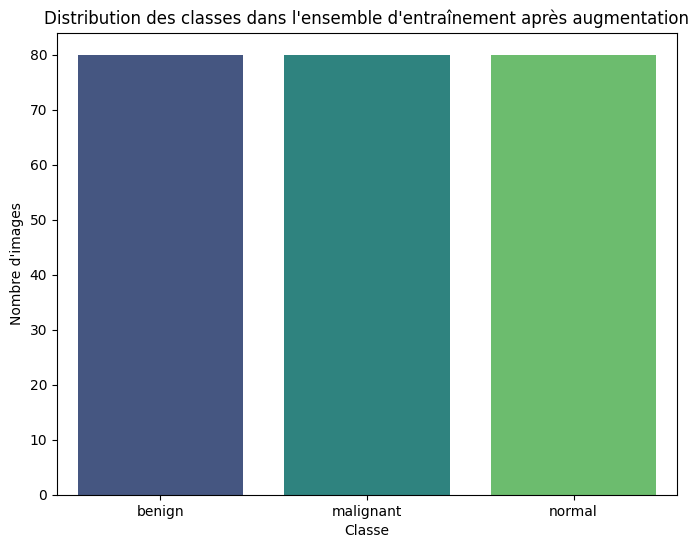

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting the class distribution after augmentation for training set
class_names_train = [label_encoder.classes_[i] for i in y_train]
class_distribution_after_aug = pd.Series(class_names_train).value_counts()

plt.figure(figsize=(8, 6))
sns.barplot(x=class_distribution_after_aug.index, y=class_distribution_after_aug.values, hue=class_distribution_after_aug.index, palette='viridis', legend=False)
plt.title("Distribution des classes dans l'ensemble d'entraînement après augmentation")
plt.xlabel('Classe')
plt.ylabel("Nombre d'images")
plt.show()

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# Let's display a few augmented images from the new training set
if 'y_train_aug' in locals() and len(y_train_aug) > 0:
    num_samples_to_display = min(5, len(y_train_aug))
    print(f"Displaying {num_samples_to_display} sample augmented images:")

    plt.figure(figsize=(15, 5))
    for i in range(num_samples_to_display):
        random_idx = np.random.randint(0, len(X_train_aug))
        plt.subplot(1, num_samples_to_display, i + 1)
        # Squeeze the channel dimension for visualization
        plt.imshow(X_train_aug[random_idx].squeeze(), cmap='gray')
        class_name = label_encoder.classes_[y_train_aug[random_idx]]
        plt.title(f"Augmented\n{class_name}")
        plt.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("No augmented images to display.")

No augmented images to display.


In [16]:
print("Les images sont normalisées et divisées en ensembles d'entraînement et de validation.")
print(f"X_train min: {X_train.min()}, max: {X_train.max()}")
print(f"X_val min: {X_val.min()}, max: {X_val.max()}")

Les images sont normalisées et divisées en ensembles d'entraînement et de validation.
X_train min: 0.003921568859368563, max: 1.0
X_val min: 0.003921568859368563, max: 1.0


In [17]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Model input shape (H, W, Channels)
input_shape = (IMG_SIZE, IMG_SIZE, 1)

# Define the CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax') # Output layer for classification
])

# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Display model summary
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,451 (12.61 MB)

 Trainable params: 3,304,451 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# Data split was done earlier to prevent data leakage.
print(f"Ready for training with {len(X_train)} training samples and {len(X_val)} validation samples.")

Ready for training with 240 training samples and 60 validation samples.


In [19]:
history = model.fit(
    X_train, y_train,
    epochs=10, # You can adjust the number of epochs
    validation_data=(X_val, y_val)
)

print("Modèle entraîné avec succès!")

Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 906ms/step - accuracy: 0.3750 - loss: 1.1069 - val_accuracy: 0.5333 - val_loss: 1.0501
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.5417 - loss: 0.9567 - val_accuracy: 0.5667 - val_loss: 0.8210
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.6167 - loss: 0.7236 - val_accuracy: 0.7500 - val_loss: 0.6283
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 833ms/step - accuracy: 0.7625 - loss: 0.5648 - val_accuracy: 0.6167 - val_loss: 0.6631
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.7583 - loss: 0.5341 - val_accuracy: 0.6500 - val_loss: 0.6308
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 832ms/step - accuracy: 0.7583 - loss: 0.4925 - val_accuracy: 0.7167 - val_loss: 0.6316
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.8083 - loss: 0.4320 - val_accuracy: 0.6333 - val_loss: 0.7021
Epoch 8/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.8458 - loss: 0.3793 - val_accuracy: 0.7167 - val_loss: 0.6489
Epo

### Exporting the Trained Model

Now that the model is trained, it's good practice to save it. This allows you to load the model later for inference or further training without re-running the entire training process.

In [23]:
from google.colab import files

# Assurez-vous que le chemin du fichier est correct
model_save_path = 'my_mammo_cnn_model.keras'

try:
    files.download(model_save_path)
    print(f"Le fichier '{model_save_path}' devrait être téléchargé sur votre machine locale.")
except Exception as e:
    print(f"Une erreur est survenue lors du téléchargement du fichier: {e}")
    print(f"Vérifiez que le fichier '{model_save_path}' existe et que vous avez l'autorisation de le télécharger.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Le fichier 'my_mammo_cnn_model.keras' devrait être téléchargé sur votre machine locale.
